# Bagging Classifier from Scratch

## Objectives
- Understand bootstrap sampling.
- Train multiple models on different bootstrap samples.
- Combine predictions using majority voting.
- Evaluate the ensemble using classification metrics.
- Compare the scratch implementation with Scikit-Learn.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [2]:
X, y = make_classification(
    n_samples=1000,
    n_features=6,
    n_informative=4,
    n_redundant=2,
    n_classes=2,
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (800, 6)
Testing shape: (200, 6)


In [3]:
class BaggingClassifierScratch:
    def __init__(self, estimator=None, n_estimators=50, random_state=42):
        self.estimator = (
            DecisionTreeClassifier()
            if estimator is None else estimator
        )
        self.n_estimators = n_estimators
        self.random_state = random_state

    def fit(self, X, y):
        X = np.asarray(X)
        y = np.asarray(y)

        if len(X) == 0:
            raise ValueError("Training data cannot be empty.")

        if len(X) != len(y):
            raise ValueError("X and y must contain the same number of samples.")

        if self.n_estimators < 1:
            raise ValueError("n_estimators must be at least 1.")

        self.classes_ = np.unique(y)
        self.estimators_ = []
        self.bootstrap_indices_ = []

        rng = np.random.default_rng(self.random_state)
        n_samples = len(X)

        for i in range(self.n_estimators):
            indices = rng.choice(
                n_samples,
                size=n_samples,
                replace=True
            )

            model = clone(self.estimator)
            model.fit(X[indices], y[indices])

            self.estimators_.append(model)
            self.bootstrap_indices_.append(indices)

        return self

    def predict(self, X):
        predictions = np.array([
            model.predict(X) for model in self.estimators_
        ])

        final_predictions = []

        for sample_predictions in predictions.T:
            counts = np.array([
                np.sum(sample_predictions == cls)
                for cls in self.classes_
            ])
            final_predictions.append(self.classes_[np.argmax(counts)])

        return np.asarray(final_predictions)

    def predict_proba(self, X):
        all_probabilities = []

        for model in self.estimators_:
            model_probabilities = model.predict_proba(X)
            aligned = np.zeros(
                (len(X), len(self.classes_)),
                dtype=float
            )

            for j, cls in enumerate(model.classes_):
                target_index = np.where(self.classes_ == cls)[0][0]
                aligned[:, target_index] = model_probabilities[:, j]

            all_probabilities.append(aligned)

        return np.mean(all_probabilities, axis=0)

In [4]:
bagging_scratch = BaggingClassifierScratch(
    estimator=DecisionTreeClassifier(random_state=42),
    n_estimators=50,
    random_state=42
)

bagging_scratch.fit(X_train, y_train)

print("Training completed.")
print("Number of estimators:", len(bagging_scratch.estimators_))

Training completed.
Number of estimators: 50


In [5]:
y_pred_scratch = bagging_scratch.predict(X_test)

print("Bagging Classifier — Scratch")
print("-" * 35)
print(f"Accuracy:  {accuracy_score(y_test, y_pred_scratch):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_scratch, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_scratch, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred_scratch, zero_division=0):.4f}")

Bagging Classifier — Scratch
-----------------------------------
Accuracy:  0.9000
Precision: 0.9082
Recall:    0.8900
F1-score:  0.8990


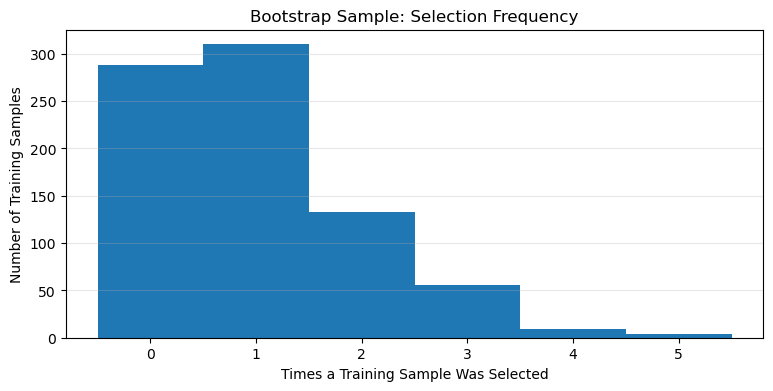

Unique samples selected: 512
Total draws: 800


In [6]:
sample_counts = np.bincount(
    bagging_scratch.bootstrap_indices_[0],
    minlength=len(X_train)
)

plt.figure(figsize=(9, 4))
plt.hist(sample_counts, bins=np.arange(sample_counts.max() + 2) - 0.5)
plt.xlabel("Times a Training Sample Was Selected")
plt.ylabel("Number of Training Samples")
plt.title("Bootstrap Sample: Selection Frequency")
plt.xticks(range(sample_counts.max() + 1))
plt.grid(axis="y", alpha=0.3)
plt.show()

print("Unique samples selected:", np.count_nonzero(sample_counts))
print("Total draws:", sample_counts.sum())

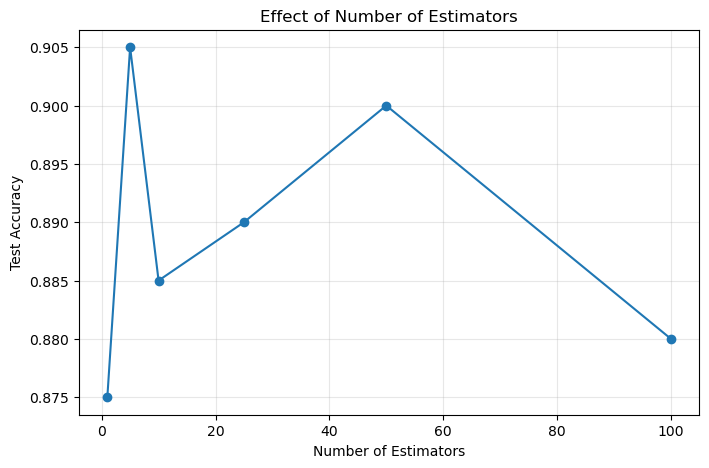

In [7]:
estimator_counts = [1, 5, 10, 25, 50, 100]
scores = []

for n in estimator_counts:
    model = BaggingClassifierScratch(
        estimator=DecisionTreeClassifier(random_state=42),
        n_estimators=n,
        random_state=42
    )
    model.fit(X_train, y_train)

    scores.append(
        accuracy_score(y_test, model.predict(X_test))
    )

plt.figure(figsize=(8, 5))
plt.plot(estimator_counts, scores, marker="o")
plt.xlabel("Number of Estimators")
plt.ylabel("Test Accuracy")
plt.title("Effect of Number of Estimators")
plt.grid(True, alpha=0.3)
plt.show()

In [8]:
sklearn_bagging = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    n_estimators=50,
    max_samples=1.0,
    bootstrap=True,
    random_state=42,
    n_jobs=-1
)

sklearn_bagging.fit(X_train, y_train)
y_pred_sklearn = sklearn_bagging.predict(X_test)

results = pd.DataFrame([
    {
        "Model": "Bagging (Scratch)",
        "Accuracy": accuracy_score(y_test, y_pred_scratch),
        "Precision": precision_score(y_test, y_pred_scratch, zero_division=0),
        "Recall": recall_score(y_test, y_pred_scratch, zero_division=0),
        "F1-score": f1_score(y_test, y_pred_scratch, zero_division=0)
    },
    {
        "Model": "Bagging (Scikit-Learn)",
        "Accuracy": accuracy_score(y_test, y_pred_sklearn),
        "Precision": precision_score(y_test, y_pred_sklearn, zero_division=0),
        "Recall": recall_score(y_test, y_pred_sklearn, zero_division=0),
        "F1-score": f1_score(y_test, y_pred_sklearn, zero_division=0)
    }
]).set_index("Model")

results.round(4)

,Accuracy,Precision,Recall,F1-score
Model,,,,
Bagging (Scratch),0.900,0.9082,0.89,0.8990
Bagging (Scikit-Learn),0.895,0.8990,0.89,0.8945


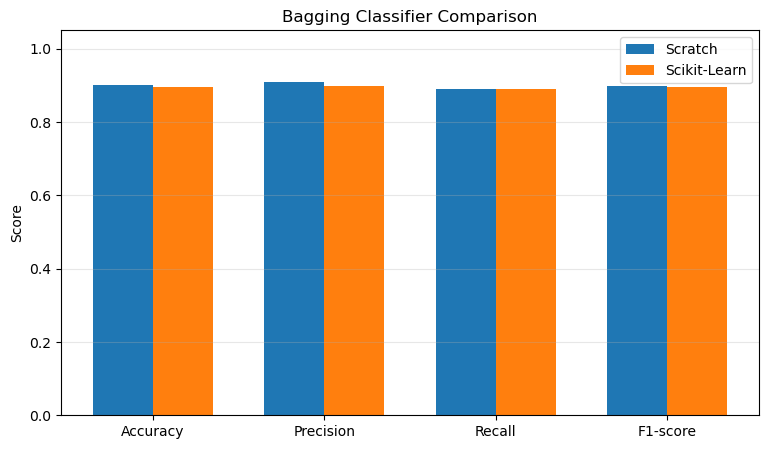

In [9]:
metrics = ["Accuracy", "Precision", "Recall", "F1-score"]
x = np.arange(len(metrics))
width = 0.35

scratch_values = results.loc["Bagging (Scratch)", metrics].values
sklearn_values = results.loc["Bagging (Scikit-Learn)", metrics].values

plt.figure(figsize=(9, 5))
plt.bar(x - width / 2, scratch_values, width, label="Scratch")
plt.bar(x + width / 2, sklearn_values, width, label="Scikit-Learn")
plt.xticks(x, metrics)
plt.ylim(0, 1.05)
plt.ylabel("Score")
plt.title("Bagging Classifier Comparison")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()

## Key Takeaways

- Bagging trains models on bootstrap samples drawn with replacement.
- Each estimator sees a slightly different training dataset.
- Classification predictions are combined using majority voting.
- Bagging can reduce variance, particularly for unstable models such as decision trees.
- More estimators may stabilize predictions, but do not guarantee higher test accuracy.
- Scikit-Learn provides an optimized implementation for practical applications.